<center><h1>Slim_Alec_HW6</h1></center>

Name: Alec Slim<br>Github Username: alecwslim<br>USC ID: 5456700424

## 1. Tree-Based Methods

Import packages

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, roc_auc_score, accuracy_score,
                             recall_score, precision_score)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier

SEED = 552
sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 180)
results = {}

### (a) Download the APS Failure data

In [2]:
# Support running from notebook/ or from the HW6 folder.
DATA = Path("../data") if Path("../data/aps_failure_training_set.csv").is_file() else Path("data")
train = pd.read_csv(DATA / "aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv(DATA / "aps_failure_test_set.csv", skiprows=20, na_values="na")
X_train, X_test = train.drop(columns="class"), test.drop(columns="class")
y_train = train["class"].map({"neg": 0, "pos": 1})
y_test = test["class"].map({"neg": 0, "pos": 1})
display(pd.DataFrame({"rows": [len(train), len(test)],
                      "features": [X_train.shape[1], X_test.shape[1]],
                      "missing entries": [X_train.isna().sum().sum(), X_test.isna().sum().sum()]},
                     index=["Training", "Test"]))

,rows,features,missing entries
Training,60000,170,850015
Test,16000,170,228680


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

There are several approaches to handle missing data including mean/median/mode imputation, nearest neighbor, and iterative regression. These can be combined with multiple imputation to represent the uncertainty in the missing values. I used median imputation for the predictors as they are skewed and have extreme values. All 170 predictors are retained. Imputation statistics are learned from training observations and reused on test observations; in cross-validation they are fitted within each training fold. The assignment's footnote reverses the usual train/test convention; using test statistics would make preprocessing depend on the evaluation data.

Source: https://scikit-learn.org/stable/modules/impute.html

#### (ii) Calculate the coefficient of variation

In [3]:
imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_eda = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)
means = X_eda.mean()
cv = (X_eda.std(ddof=1) / means.replace(0, np.nan)).rename("CV")
display(cv.to_frame())

,CV
aa_000,2.450938
ab_000,10.383494
ac_000,2.310241
ad_000,244.322816
ae_000,24.200137
af_000,19.471295
ag_000,92.917755
ag_001,35.249314
ag_002,17.565907
ag_003,8.647402


#### (iii) Plot a correlation matrix

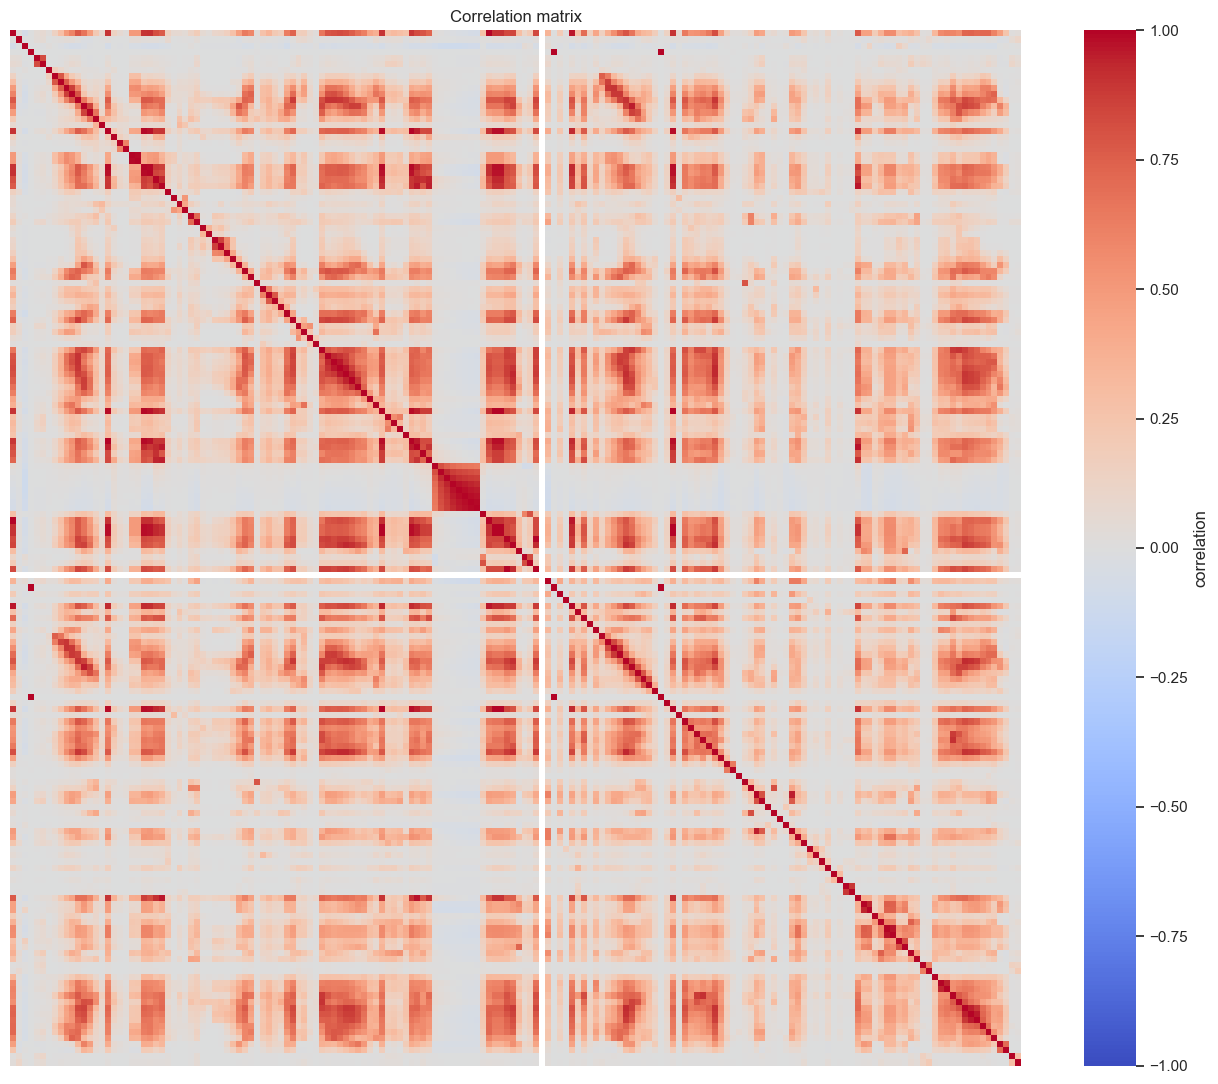

In [4]:
plt.figure(figsize=(13, 11))
sns.heatmap(X_eda.corr(), cmap="coolwarm", vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False, cbar_kws={"label": "correlation"})
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

13 highest features: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


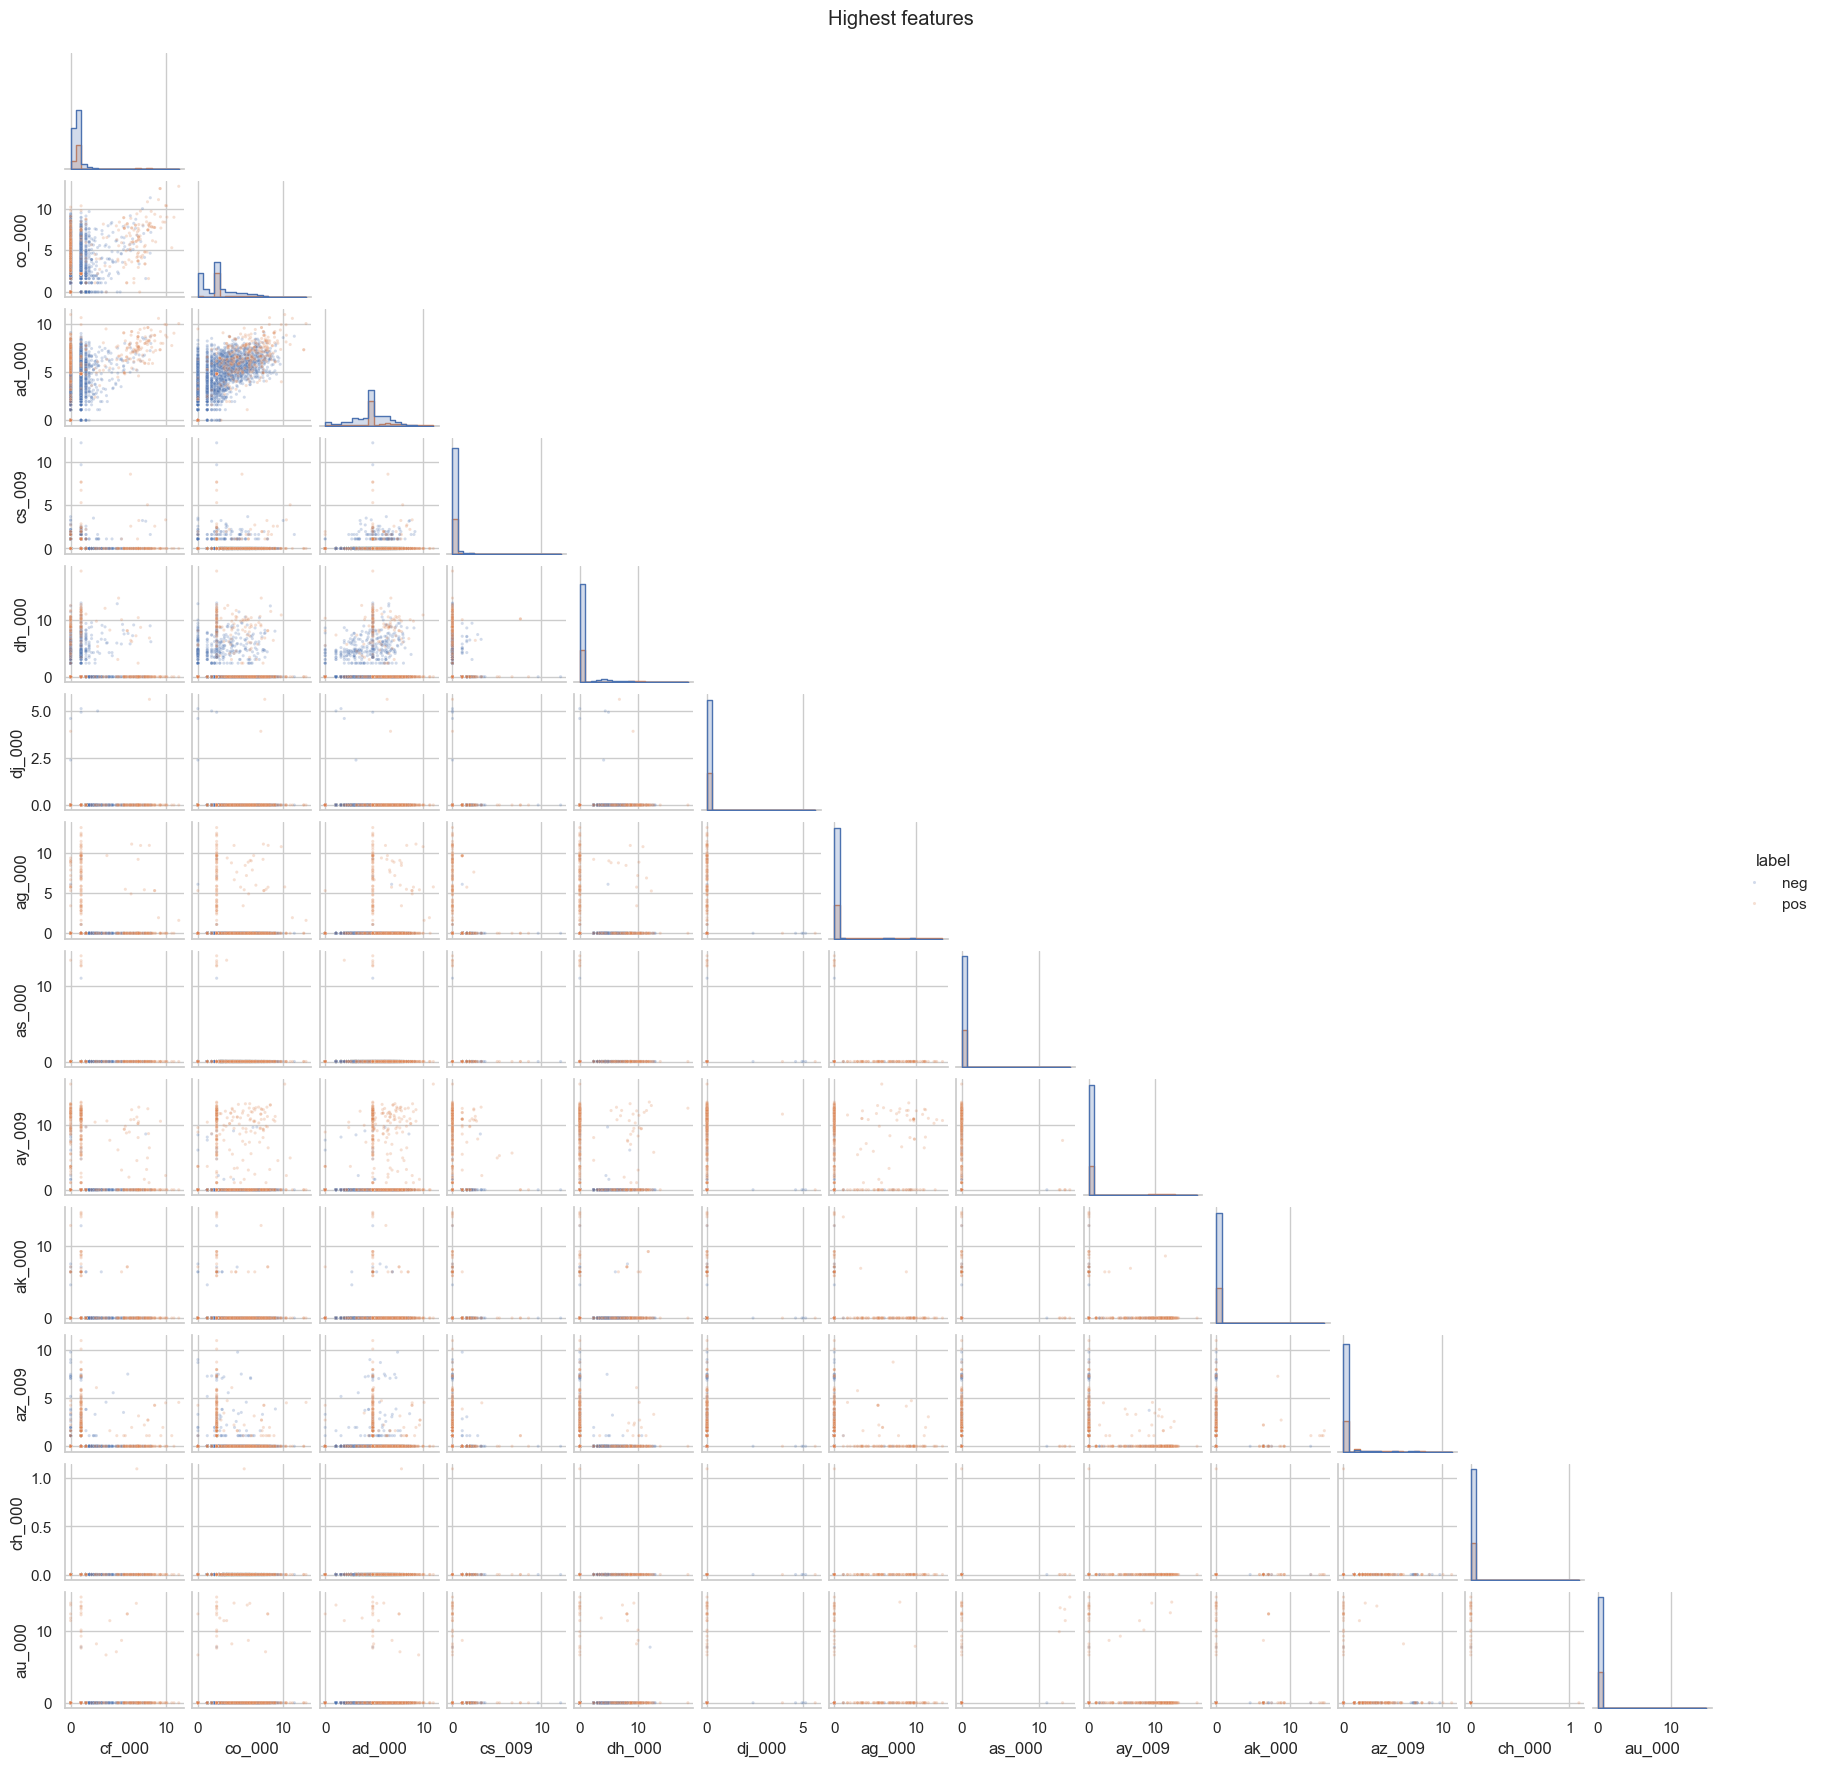

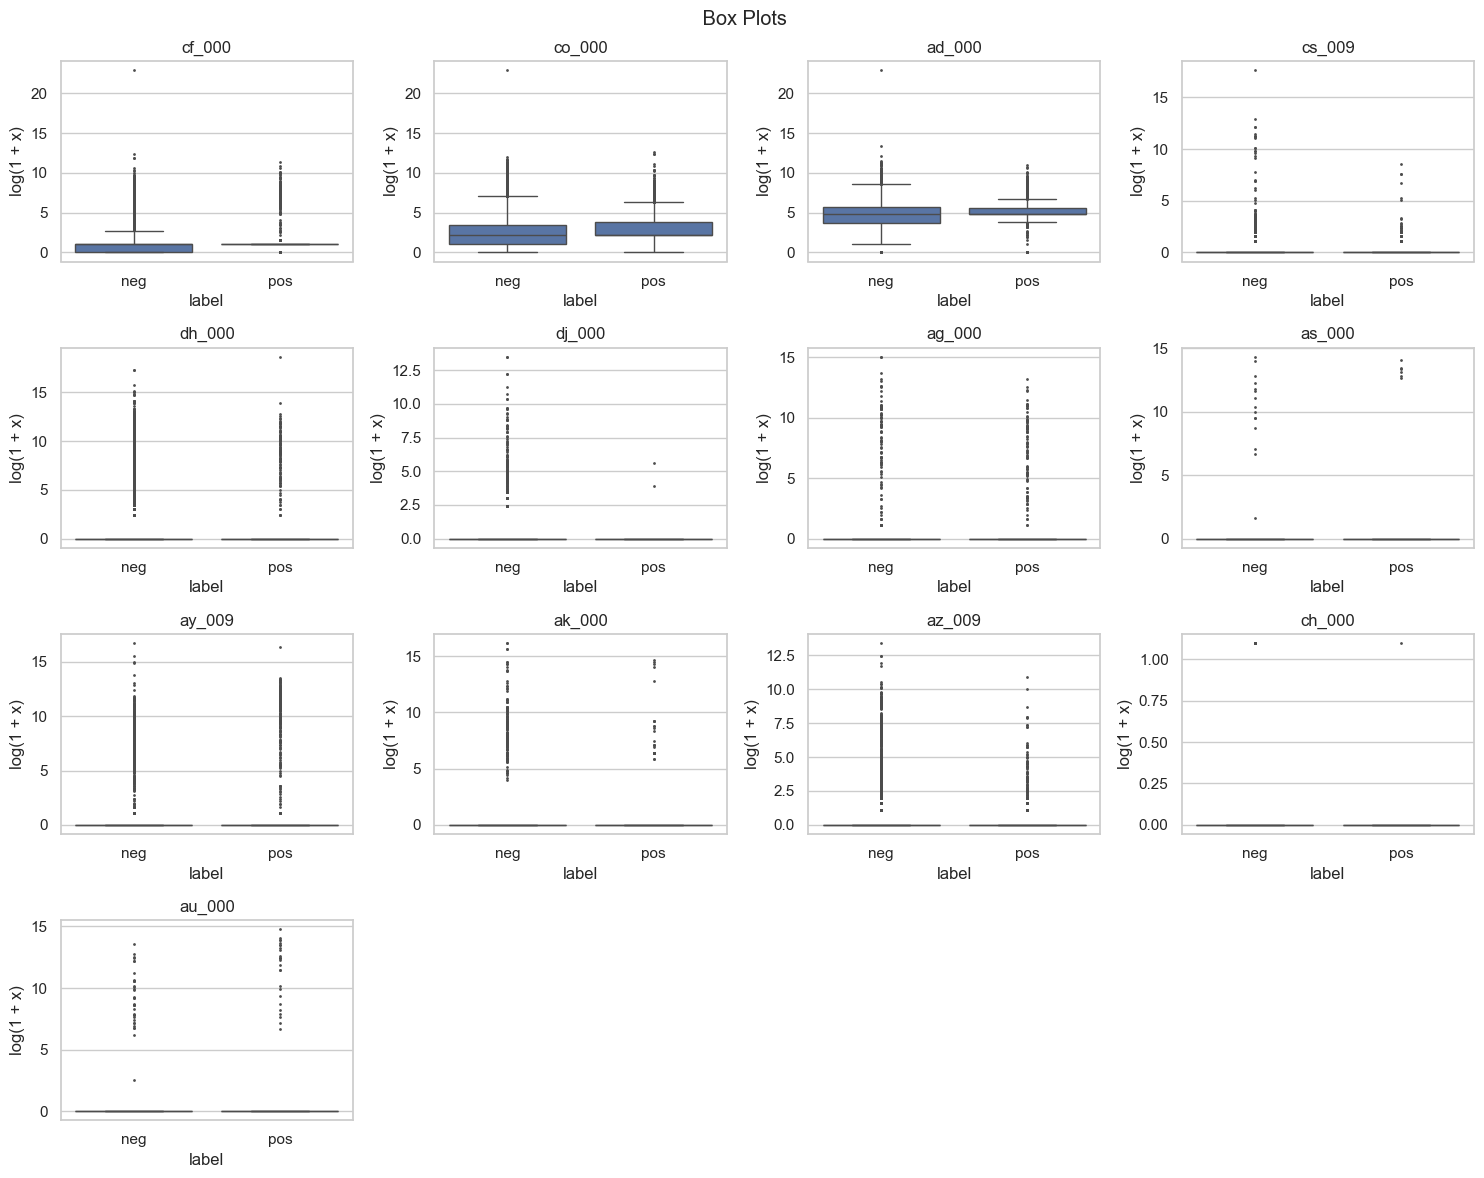

In [5]:
top_features = cv.nlargest(int(np.sqrt(X_train.shape[1]))).index.tolist()
print("13 highest features:", top_features)
plot_data = np.log1p(X_eda[top_features]).assign(label=train["class"])
scatter_data = plot_data.groupby("label", group_keys=False).sample(frac=1, random_state=SEED)
scatter_data = scatter_data.groupby("label", group_keys=False).head(3000)
g = sns.pairplot(scatter_data, hue="label", hue_order=["neg", "pos"],
                 corner=True, diag_kind="hist", height=1.35,
                 plot_kws={"s": 5, "alpha": 0.25, "rasterized": True},
                 diag_kws={"bins": 20, "element": "step"})
g.figure.suptitle("Highest features", y=1.01)
plt.show()
fig, axes = plt.subplots(4, 4, figsize=(15, 12))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(data=plot_data, x="label", y=feature, order=["neg", "pos"],
                ax=ax, fliersize=1)
    ax.set_ylabel("log(1 + x)")
    ax.set_title(feature)
for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)
fig.suptitle(" Box Plots")
plt.tight_layout()
plt.show()

Several features contain many zeros and long right tails that overlap considerably between classes. Some class distributions differ significantly however, a high CV does not necessarily indicate a high predictive significance. Scatter plots alone do not establish statistical significance or conditional usefulness.

#### (v) Is this data set imbalanced?

In [6]:
counts = pd.DataFrame({"Training": y_train.value_counts(), "Test": y_test.value_counts()})
counts.index = ["Negative (0)", "Positive (1)"]
display(counts)

,Training,Test
Negative (0),59000,15625
Positive (1),1000,375


Yes the dataset is extremely imbalanced with a 59:1 negative to positive ratio. 

### (c) Train a random forest

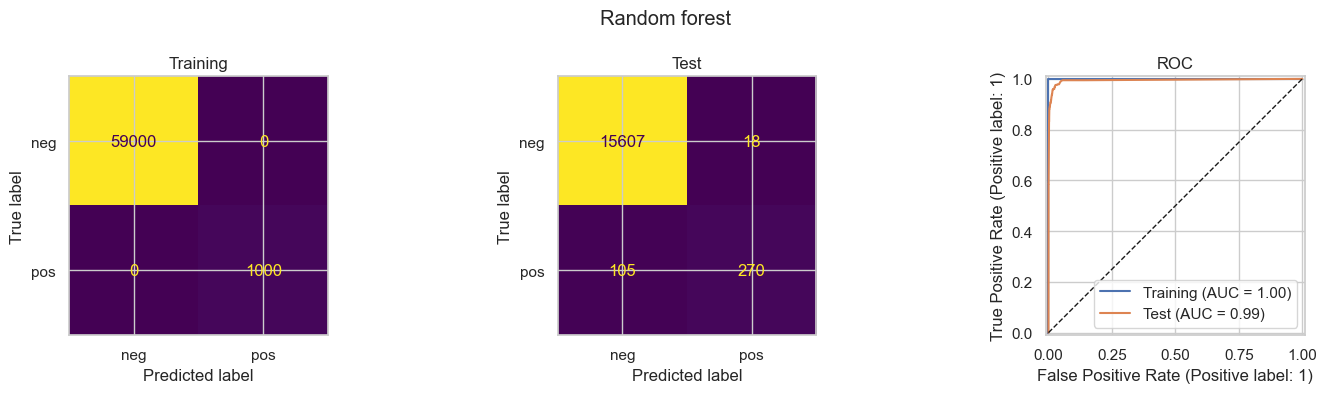

,Misclassification,AUC,Positive recall,Positive precision,TN,FP,FN,TP
Split,,,,,,,,
Training,0.000000,1.000000,1.00,1.0000,59000,0,0,1000
Test,0.007687,0.994449,0.72,0.9375,15607,18,105,270


OOB error = 0.00568; test error = 0.00769.
Test minus OOB error = +0.00200.


In [7]:
def evaluate(name, model):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    rows = []
    for split, X, y, ax in [("Training", X_train, y_train, axes[0]),
                             ("Test", X_test, y_test, axes[1])]:
        prob = model.predict_proba(X)[:, 1]
        pred = (prob >= 0.5).astype(int)
        cm = confusion_matrix(y, pred, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["neg", "pos"]).plot(ax=ax, colorbar=False)
        ax.set_title(split)
        RocCurveDisplay.from_predictions(y, prob, name=split, ax=axes[2])
        rows.append({"Split": split, "Misclassification": 1 - accuracy_score(y, pred),
                     "AUC": roc_auc_score(y, prob), "Positive recall": recall_score(y, pred),
                     "Positive precision": precision_score(y, pred, zero_division=0),
                     "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]})
    axes[2].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[2].set_title("ROC")
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()
    table = pd.DataFrame(rows).set_index("Split")
    results[name] = table
    display(table)
    return table

rf = Pipeline([("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
               ("model", RandomForestClassifier(n_estimators=300, max_features="sqrt",
                         oob_score=True, class_weight=None, random_state=SEED, n_jobs=4))])
rf.fit(X_train, y_train)
rf_metrics = evaluate("Random forest", rf)
rf_oob = 1 - rf.named_steps["model"].oob_score_
print(f"OOB error = {rf_oob:.5f}; test error = {rf_metrics.loc['Test', 'Misclassification']:.5f}.")
print(f"Test minus OOB error = {rf_metrics.loc['Test', 'Misclassification'] - rf_oob:+.5f}.")

### (d) Research class imbalance in random forest

The imbalance in the random forest can be addressed with the inverse-frequency class weights, with balanced bootstrap sampling, with oversampling/SMOTE, with undersampling, or with a validation-selected decision threshold. I use the balanced_subsample method that recomputes the inverse-frequency weights in each bootstrap sample. The forest is otherwise constructed as in (c).

Source: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

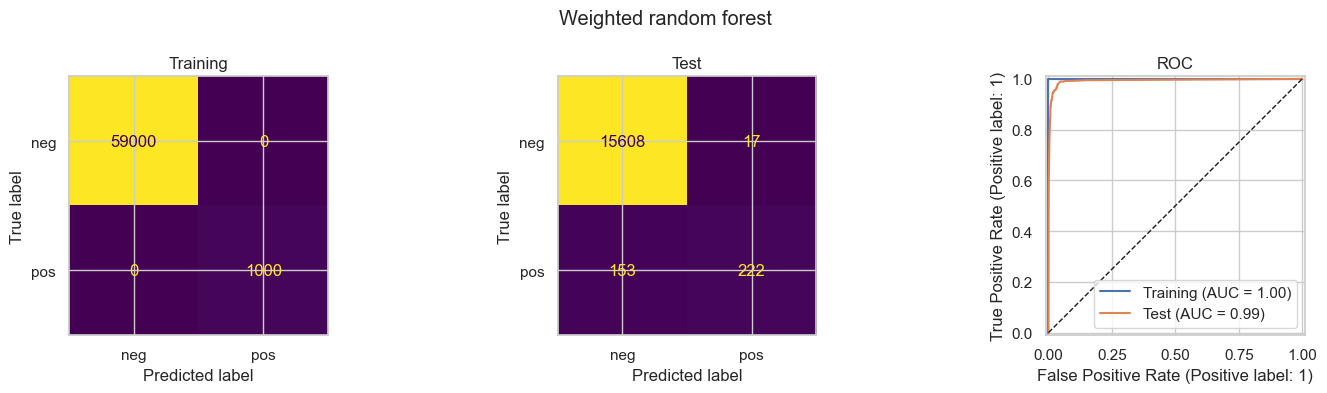

,Misclassification,AUC,Positive recall,Positive precision,TN,FP,FN,TP
Split,,,,,,,,
Training,0.000000,1.0000,1.000,1.00000,59000,0,0,1000
Test,0.010625,0.9931,0.592,0.92887,15608,17,153,222


OOB error = 0.00757; test error = 0.01062.


,Misclassification,AUC,Positive recall,Positive precision,TN,FP,FN,TP,OOB error
Unweighted,0.007687,0.994449,0.720,0.93750,15607.0,18.0,105.0,270.0,0.005683
Weighted,0.010625,0.993100,0.592,0.92887,15608.0,17.0,153.0,222.0,0.007567


In [8]:
rf_balanced = Pipeline([
    ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("model", RandomForestClassifier(n_estimators=300, max_features="sqrt",
              oob_score=True, class_weight="balanced_subsample", random_state=SEED, n_jobs=4))])
rf_balanced.fit(X_train, y_train)
rf_balanced_metrics = evaluate("Weighted random forest", rf_balanced)
rf_balanced_oob = 1 - rf_balanced.named_steps["model"].oob_score_
print(f"OOB error = {rf_balanced_oob:.5f}; test error = {rf_balanced_metrics.loc['Test', 'Misclassification']:.5f}.")
comparison_rf = pd.DataFrame({"Unweighted": rf_metrics.loc["Test"],
                              "Weighted": rf_balanced_metrics.loc["Test"]}).T
comparison_rf["OOB error"] = [rf_oob, rf_balanced_oob]
display(comparison_rf)

The weighted forest missed 153 positives, while the unweighted forest missed 105. Test error increased from 0.7688% to 1.0625%, recall decreased from 72.0% to 59.2%, and AUC decreased from 0.9944 to 0.9931. Weighted forests did not improve performance at a threshold of 0.5. Both forests achieved 100% training accuracy. Weighted forest’s OOB error was 0.7567%, i.e. 0.3058 percentage points lower than the test error of weighted forest.

### (e) XGBoost and Model Trees

,alpha,Mean CV error,SD across folds
0,0.00000,0.008367,5.180090e-04
1,0.00001,0.008383,5.071708e-04
2,0.00010,0.008450,6.699917e-04
3,0.00100,0.009700,9.924717e-04
4,0.01000,0.012800,8.242842e-04
5,0.10000,0.016667,1.110223e-16


Selected alpha: 0


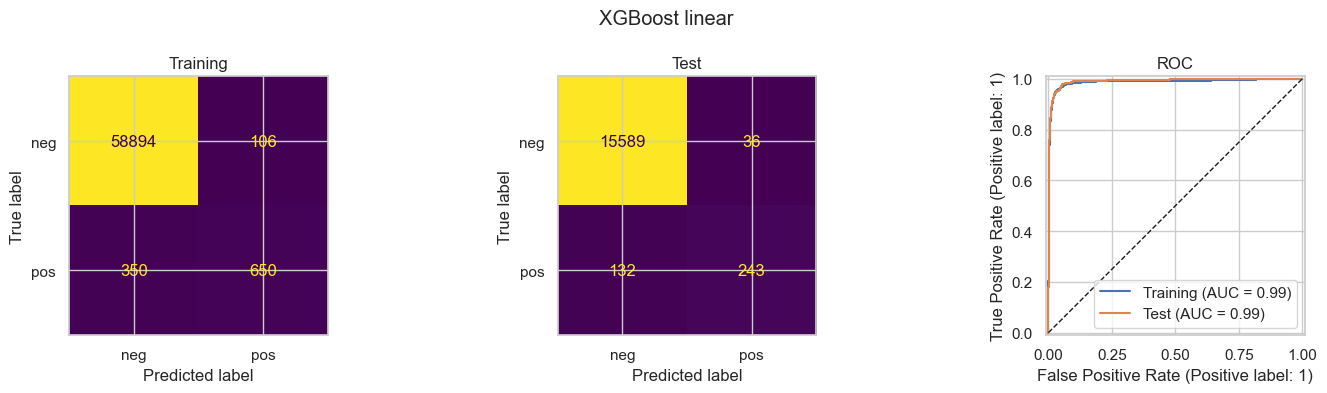

,Misclassification,AUC,Positive recall,Positive precision,TN,FP,FN,TP
Split,,,,,,,,
Training,0.0076,0.988110,0.650,0.859788,58894,106,350,650
Test,0.0105,0.992314,0.648,0.870968,15589,36,132,243


Selected-model 5-fold CV error = 0.00837; test error = 0.01050.


In [9]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
alpha_grid = [0, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

def xgb_pipeline(smote=False):
    steps = [("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
             ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
             ("scale", StandardScaler())]
    if smote:
        steps.append(("smote", SMOTE(random_state=SEED, k_neighbors=5)))
    steps.append(("model", XGBClassifier(
        booster="gblinear", objective="binary:logistic", reg_lambda=0,
        n_estimators=300, learning_rate=0.1, updater="coord_descent",
        feature_selector="cyclic", random_state=SEED, n_jobs=4,
        eval_metric="logloss")))
    return Pipeline(steps)

def tune_xgb(smote=False):
    search = GridSearchCV(xgb_pipeline(smote), {"model__reg_alpha": alpha_grid},
                          scoring="accuracy", cv=folds, n_jobs=1, refit=True)
    search.fit(X_train, y_train)
    cv_table = pd.DataFrame({"alpha": alpha_grid,
                             "Mean CV error": 1 - search.cv_results_["mean_test_score"],
                             "SD across folds": search.cv_results_["std_test_score"]})
    display(cv_table)
    print("Selected alpha:", search.best_params_["model__reg_alpha"])
    return search

xgb_search = tune_xgb()
xgb_metrics = evaluate("XGBoost linear", xgb_search.best_estimator_)
xgb_cv_error = 1 - xgb_search.best_score_
print(f"Selected-model 5-fold CV error = {xgb_cv_error:.5f}; test error = {xgb_metrics.loc['Test', 'Misclassification']:.5f}.")

The model selection by Cross Validation (CV) was performed using the l1 regularization family, with alpha being set to 0 as the unpenalized boundary. Increasing positive penalty values increased CV error. Selected model CV error was found to be .8367% on the CV data set while the test set error was 1.0500%, for a difference of .2133 percentage points between the two errors. Test AUC was .9923 with positive recall being 64.8%. Positive class proportion in the test set was larger than that in the training set.

### (f) Use SMOTE to pre-process your data

,alpha,Mean CV error,SD across folds
0,0.00000,0.037350,0.002011
1,0.00001,0.037383,0.001980
2,0.00010,0.037417,0.002127
3,0.00100,0.039183,0.001862
4,0.01000,0.048017,0.001384
5,0.10000,0.061967,0.003205


Selected alpha: 0


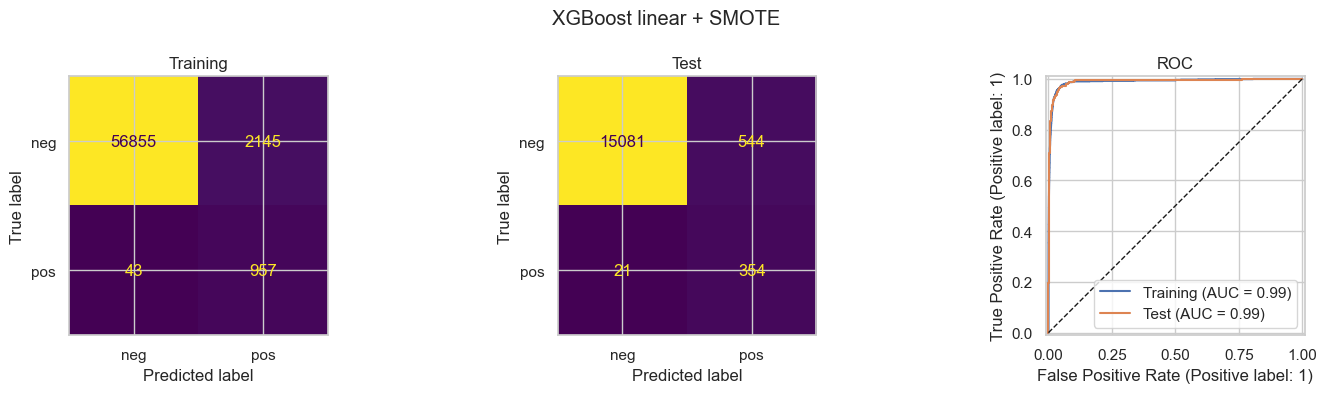

,Misclassification,AUC,Positive recall,Positive precision,TN,FP,FN,TP
Split,,,,,,,,
Training,0.036467,0.989333,0.957,0.308511,56855,2145,43,957
Test,0.035312,0.990880,0.944,0.394209,15081,544,21,354


Selected-model 5-fold CV error = 0.03735; test error = 0.03531.


,Misclassification,AUC,Positive recall,Positive precision,TN,FP,FN,TP,CV error
Uncompensated,0.010500,0.992314,0.648,0.870968,15589.0,36.0,132.0,243.0,0.008367
SMOTE,0.035312,0.990880,0.944,0.394209,15081.0,544.0,21.0,354.0,0.037350


In [10]:
xgb_smote_search = tune_xgb(smote=True)
xgb_smote_metrics = evaluate("XGBoost linear + SMOTE", xgb_smote_search.best_estimator_)
xgb_smote_cv_error = 1 - xgb_smote_search.best_score_
print(f"Selected-model 5-fold CV error = {xgb_smote_cv_error:.5f}; test error = {xgb_smote_metrics.loc['Test', 'Misclassification']:.5f}.")
comparison_xgb = pd.DataFrame({"Uncompensated": xgb_metrics.loc["Test"],
                               "SMOTE": xgb_smote_metrics.loc["Test"]}).T
comparison_xgb["CV error"] = [xgb_cv_error, xgb_smote_cv_error]
display(comparison_xgb)

SMOTE also selects alpha = 0. The CV error is 3.7350%, as compared to the test error of 3.5313%. The test recall for SMOTE is 94.4%, up from 64.8% for uncompensated XGBoost, but the number of false positives has gone up from 36 to 544. The test error has increased from 1.0500% to 3.5313%, and the precision has gone down from 87.10% to 39.42%. The AUC has decreased slightly from 0.9923 to 0.9909.

## 2. ISLR 6.6.3

**(a) iv.** Training RSS is nonincreasing with increasing $s$. The set of feasible points is increasing and so the minimum over this set cannot increase. Once the least-squares solution is in the feasible set, then the training RSS remains constant.

**(b) ii.** As $s$ increases, test RSS typically falls at first and then rises. This U-shaped pattern is common but not guaranteed. This is because we start by reducing the amount of underfitting, and then we increase the variance and consequently the amount of overfitting.

**(c) iii.** Variance generally increases as the fit becomes less constrained.

**(d) iv.** Squared bias generally decreases as the fit becomes more flexible.

**(e) v.** Irreducible error remains constant as $s$ is changed because there is no change to the noise in the data-generating process.

## 3. ISLR 6.6.5

Let $x_i=x_{i1}=x_{i2}$ for $i=1,2$, $S=\sum_{i=1}^2x_i^2$, $T=\sum_{i=1}^2x_iy_i$. The intercept is zero.

**(a)**
$$\min_{\beta_1,\beta_2}\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(\beta_1^2+\beta_2^2).$$

**(b)** For $\lambda>0$, $t=\beta_1+\beta_2$. The RSS depends only on $t$, when
$$\beta_1^2+\beta_2^2=\frac{t^2+(\beta_1-\beta_2)^2}{2}$$
For a given value of $t$, the term $\beta_1^2+\beta_2^2$ is minimized for $\beta_1=\beta_2=t/2$. Both estimates equal $T/(2S+\lambda)$ for $\lambda>0$. At $\lambda=0$ both estimates may equal $T/(2S)$ but do not have to because the solution to the least squares problem is not unique.

**(c)**
$$\min_{\beta_1,\beta_2}\sum_{i=1}^{2}[y_i-x_i(\beta_1+\beta_2)]^2+\lambda(|\beta_1|+|\beta_2|).$$

**(d)** For fixed $t$, the minimum penalty is $\lambda|t|$ which is attained for all coefficients of the same sign. For $S>0$, the solution is $t^*=\frac{\operatorname{sign}(T)(|T|-\lambda/2)_+}{S}$ where $t^*$ is the shrinkage of $T$ by $\lambda/2$. All solutions are of the form $(\hat\beta_1,\hat\beta_2)=(a,t^*-a)$ with $a\in[0,t^*]$ for $t^*>0$ and $a\in[t^*,0]$ for $t^*<0$. There are infinitely many solutions for $t^*\ne0$. For $t^*=0$ and $\lambda>0$, the unique solution is $(0,0)$. nonuniqueness is not unconditional.

## 4. ISLR 8.4.5

**Majority vote:** Six out of ten trees give a probability higher than 0.5 for Red so the prediction is Red. There are six votes for Red and four votes, for Green.

**Average probability:** The average is 4.50 divided by 10 which equals 0.45 so the prediction is Green.

## 5. ISLR 9.7.3

**(a)** Plot below.

**(b)** $\tfrac12-X_1+X_2=0$, or $X_2=X_1-\tfrac12$.

**(c)** Predict Red if $\tfrac12-X_1+X_2>0$ and Blue otherwise: $(\beta_0,\beta_1,\beta_2)=(\tfrac12,-1,1)$.

**(d)** shown bleow

**(e)** The support vectors are 2 $(2,2)$, 3 $(4,4)$, 5 $(2,1)$, and 6 $(4,3)$.

**(f)** Observation 7, $(4,1)$, is strictly outside the margin. A sufficiently small movement keeps it outside the margin and does not change the supporting boundaries or optimal hyperplane.

**(g)** An alternative separating line is $X_2=X_1-\tfrac14$ but with minimum distance to any point of $1/(4\sqrt2)$ instead of the optimal $1/(2\sqrt2)$ margin.

**(h)** Add a Blue observation at $(3,3)$, which lies on the line segment joining the two Red observations 2 and 3. All positive affine functions on the line segment joining the two Red observations 2 and 3 are also positive at the midpoint of the line segment joining the two Red observations 2 and 3. Therefore, no hyperplane can strictly separate all the labels.

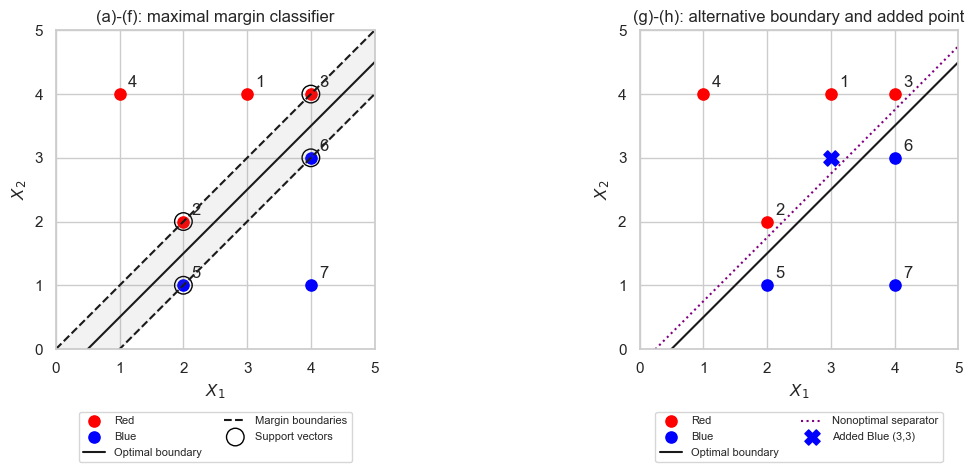

In [11]:
points = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
x = np.linspace(0, 5, 200)
for ax in axes:
    ax.scatter(points[:4, 0], points[:4, 1], c="red", label="Red", s=65)
    ax.scatter(points[4:, 0], points[4:, 1], c="blue", label="Blue", s=65)
    for i, (x1, x2) in enumerate(points, start=1):
        ax.annotate(str(i), (x1, x2), xytext=(6, 5), textcoords="offset points")
    ax.plot(x, x - 0.5, "k-", label="Optimal boundary")
    ax.set(xlim=(0, 5), ylim=(0, 5), xlabel="$X_1$", ylabel="$X_2$")
    ax.set_aspect("equal")
axes[0].plot(x, x, "k--", label="Margin boundaries")
axes[0].plot(x, x - 1, "k--")
axes[0].scatter(points[[1, 2, 4, 5], 0], points[[1, 2, 4, 5], 1],
                facecolors="none", edgecolors="black", s=160, label="Support vectors")
axes[0].fill_between(x, x, x - 1, alpha=0.1, color="gray")
axes[0].set_title("(a)-(f): maximal margin classifier")
axes[1].plot(x, x - 0.25, color="purple", linestyle=":", label="Nonoptimal separator")
axes[1].scatter([3], [3], c="blue", marker="X", s=120, label="Added Blue (3,3)")
axes[1].set_title("(g)-(h): alternative boundary and added point")
for ax in axes:
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=8)
plt.tight_layout()
plt.show()